# Bayesian Comparison
Statistical comparison of the systems trained in `Experiments.ipynb`. This notebook only reads the scores the experiments
saved to `results/<experiment>/cv_scores.csv` (and `test_scores.csv`), so it needs no retraining and no data loading.
Every system with saved scores in `results/` is included automatically (e.g. the two-hidden-layer MLPs, or a CNN once it
has been run).

In [6]:
from itertools import combinations
from pathlib import Path

import numpy as np
import pandas as pd

import part1  # to use code from tutorial

# must match Experiments.ipynb
results_folder = Path("./results")
my_seeds = [0, 1, 2]

def load_scores(kind="cv"):
    """All saved scores of one kind ("cv" or "test"), one row per (model, seed, fold)."""
    frames = [pd.read_csv(path).assign(model=path.parent.name) for path in sorted(results_folder.glob(f"*/{kind}_scores.csv"))]
    return pd.concat(frames, ignore_index=True)[["model", "seed", "fold", "accuracy", "f1"]]

In [7]:
# test-set scores (mean and std over the fold models), for reference
load_scores("test").groupby("model")[["accuracy", "f1"]].agg(["mean", "std"]).round(4)

accuracy              f1        
                              mean     std    mean     std
model                                                     
logistic_bow-lemmas         0.6845  0.0024  0.6309  0.0059
logistic_embeddings         0.6559  0.0005  0.5911  0.0005
logistic_indicator-lemmas   0.6890  0.0007  0.6443  0.0009
mlp2_bow-lemmas             0.6998  0.0013  0.6629  0.0045
mlp2_embeddings             0.6831  0.0015  0.6468  0.0058
mlp2_indicator-lemmas       0.6986  0.0014  0.6654  0.0040
mlp_bow-lemmas              0.7005  0.0010  0.6627  0.0048
mlp_embeddings              0.6879  0.0012  0.6521  0.0035
mlp_indicator-lemmas        0.7008  0.0014  0.6648  0.0036

In [ ]:
# full results table (mean ± std over the fold models, 3 seeds x 5 folds), saved to figures/results_table.csv
# for the slides (import it in Google Sheets with File -> Import, then copy the cells into Slides)
ARCHITECTURES = {"logistic": "Log-lin", "mlp": "MLP", "mlp2": "MLP (2 layers)"}
REPRESENTATIONS = {"indicator-lemmas": "Token indicator", "bow-lemmas": "Bag of words", "embeddings": "Sentence embeddings"}
COLUMNS = [("cv", "accuracy", "CV accuracy"), ("cv", "f1", "CV macro F1"),
           ("test", "accuracy", "Test accuracy"), ("test", "f1", "Test macro F1")]

scores = {kind: load_scores(kind) for kind in ("cv", "test")}
rows = []
for arch, arch_name in ARCHITECTURES.items():
    for rep, rep_name in REPRESENTATIONS.items():
        model = f"{arch}_{rep}"
        if model not in set(scores["cv"]["model"]):
            continue
        row = {"Model": arch_name, "Representation": rep_name}
        for kind, metric, column in COLUMNS:
            values = scores[kind].loc[scores[kind]["model"] == model, metric]
            row[column] = f"{values.mean():.3f} ± {values.std():.3f}"
        rows.append(row)

# majority-class baseline: always predicting Right, the larger class (313,849 of the 505,370 Left/Right sentences;
# train and test have the same share, the split is stratified). Its macro F1 is p / (1 + p).
p = 313_849 / 505_370
baseline = {"accuracy": f"{p:.3f}", "f1": f"{p / (1 + p):.3f}"}
rows.append({"Model": "Majority-class baseline", "Representation": "–",
             **{column: baseline[metric] for _, metric, column in COLUMNS}})

results_table = pd.DataFrame(rows)
Path("./figures").mkdir(exist_ok=True)
results_table.to_csv("./figures/results_table.csv", index=False, encoding="utf-8")
results_table

## ROPE Analysis: Picking Amongst Design Choices
Following the tutorial (*Picking Amongst Design Choices*), we compare systems with the Bayesian correlated t-test of
[Benavoli et al. 2017](https://jmlr.org/papers/volume18/16-305/16-305.pdf), via `part1.analysis.BenavoliCorrelatedT`.
It gives a posterior over the mean difference in performance (B − A) across the cross-validation folds, and the probability
that this difference lies left of, inside, or right of a region of practical equivalence (ROPE).

* **Metric:** macro F1 on the validation folds (the classes are imbalanced, so accuracy is also reported for comparison).
* **Data:** the per-fold scores saved in `results/<experiment>/cv_scores.csv`, so this section needs no retraining.
* **Runs:** each seed is a separate run of 5-fold cross-validation (`runs=len(my_seeds)`), so the test corrects for the
  correlation between folds of the same run. Folds are paired: for a given seed and fold, all systems were trained and
  validated on the same rows.
* **ROPE:** ±0.01 (one point of F1 or accuracy); the tutorial uses ±0.005.

In [8]:
# settings for the analysis
ROPE_SIZE = 0.01         # differences smaller than this (in F1 / accuracy) count as practically equivalent
DECISION_PROB = 0.95     # a region (A wins / tie / B wins) needs at least this posterior probability to call a decision

cv_scores = load_scores("cv")  # one row per (model, seed, fold), with accuracy and macro F1
cv_scores.groupby("model")[["accuracy", "f1"]].agg(["mean", "std"]).round(4)

accuracy              f1        
                              mean     std    mean     std
model                                                     
logistic_bow-lemmas         0.6851  0.0030  0.6323  0.0065
logistic_embeddings         0.6569  0.0018  0.5930  0.0019
logistic_indicator-lemmas   0.6903  0.0015  0.6466  0.0015
mlp2_bow-lemmas             0.7009  0.0018  0.6643  0.0050
mlp2_embeddings             0.6848  0.0018  0.6491  0.0048
mlp2_indicator-lemmas       0.7008  0.0016  0.6682  0.0046
mlp_bow-lemmas              0.7021  0.0015  0.6649  0.0050
mlp_embeddings              0.6891  0.0019  0.6538  0.0040
mlp_indicator-lemmas        0.7032  0.0021  0.6678  0.0037

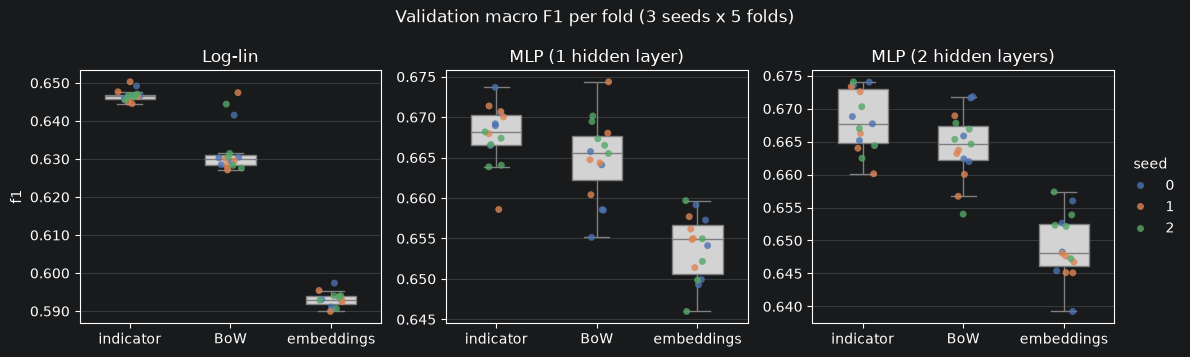

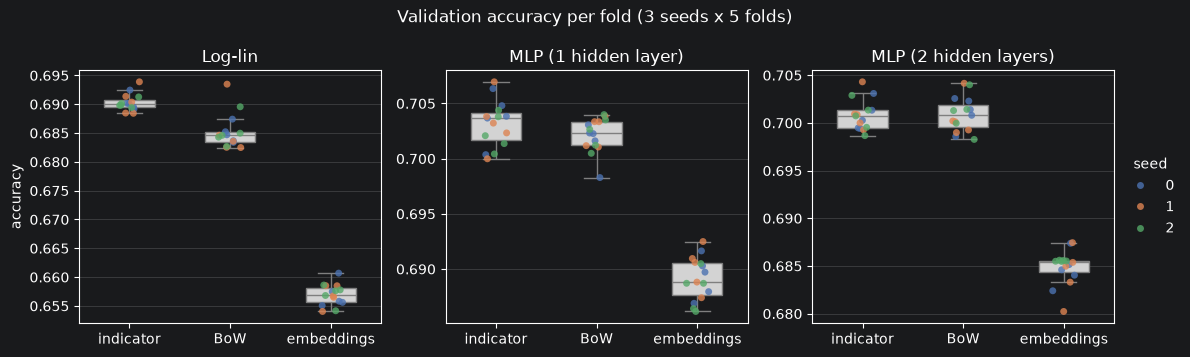

In [9]:
# fold scores per system, as in the tutorial, but split into one panel per architecture so each panel shows only
# the three representations (each panel has its own y-axis range; mind the scale when comparing across panels)
import matplotlib.pyplot as plt
import seaborn as sns

FAMILIES = {"logistic": "Log-lin", "mlp": "MLP (1 hidden layer)", "mlp2": "MLP (2 hidden layers)"}
REPRESENTATIONS = {"indicator-lemmas": "indicator", "bow-lemmas": "BoW", "embeddings": "embeddings"}

def plot_fold_scores(scores, metric="f1"):
    """Box plot plus one dot per (seed, fold) score, one panel per architecture."""
    parts = scores["model"].str.split("_", n=1, expand=True)  # e.g. "mlp2_bow-lemmas" -> "mlp2", "bow-lemmas"
    data = scores.assign(family=parts[0], representation=parts[1].map(REPRESENTATIONS))
    families = [f for f in FAMILIES if f in set(data["family"])]
    fig, axes = plt.subplots(1, len(families), figsize=(4 * len(families), 3.6), squeeze=False)
    for ax, fam in zip(axes[0], families):
        panel = data[data["family"] == fam]
        order = [r for r in REPRESENTATIONS.values() if r in set(panel["representation"])]
        sns.boxplot(data=panel, x="representation", y=metric, order=order, color="lightgray",
                    showfliers=False, width=0.5, ax=ax)
        sns.stripplot(data=panel, x="representation", y=metric, hue="seed", order=order, palette="deep",
                      jitter=0.12, size=5, alpha=0.8, ax=ax, legend=ax is axes[0][-1])
        ax.set(title=FAMILIES[fam], xlabel="", ylabel=metric if ax is axes[0][0] else "")
        ax.grid(axis="y", alpha=0.3)
        ax.yaxis.set_major_formatter("{x:.3f}")
    axes[0][-1].legend(title="seed", loc="center left", bbox_to_anchor=(1, 0.5), frameon=False)
    fig.suptitle(f"Validation {'macro F1' if metric == 'f1' else metric} per fold (3 seeds x 5 folds)")
    fig.tight_layout()
    plt.show()

plot_fold_scores(cv_scores, metric="f1")
plot_fold_scores(cv_scores, metric="accuracy")

In [10]:
# First, a little helper, to gather all measurements across runs and folds, in the same (seed, fold) order for every
# system, so the scores of two systems are paired
def get_all_measurements_for(scores, sys_name, metric="f1"):
    table = scores[scores["model"] == sys_name].pivot(index="seed", columns="fold", values=metric)
    table = table.loc[my_seeds].sort_index(axis=1)  # rows: runs (seeds), columns: folds
    assert not table.isna().any().any(), f"missing folds for {sys_name}"
    return table.to_numpy()

# this will have shape [num_runs, num_folds]
get_all_measurements_for(cv_scores, "logistic_indicator-lemmas")

array([[0.64916772, 0.64553361, 0.64625763, 0.64665079, 0.64589397],
       [0.64454971, 0.64645431, 0.65028519, 0.64766638, 0.64496026],
       [0.64661802, 0.64668873, 0.64705819, 0.64556719, 0.64638069]])

A=logistic_indicator-lemmas B=mlp_indicator-lemmas: P(A wins)=0.0000 P(Tie)=0.0000 P(B wins)=1.0000 Effect Size=11.88


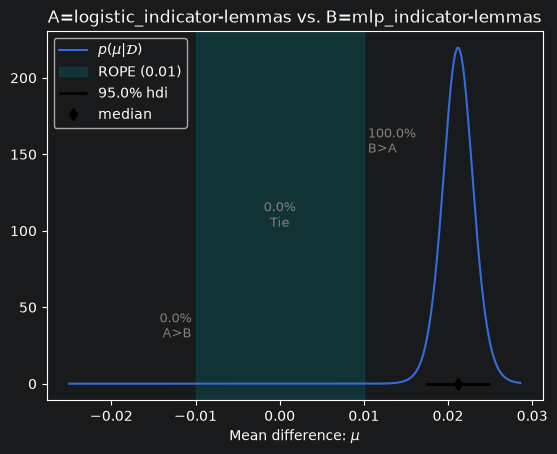

In [11]:
def compare(sys_a, sys_b, metric="f1", scores=cv_scores):
    """Posterior over the mean difference (B - A) between two systems, from their paired fold scores."""
    return part1.analysis.BenavoliCorrelatedT(
        get_all_measurements_for(scores, sys_a, metric).flatten(),  # shape [num_runs * num_folds]
        get_all_measurements_for(scores, sys_b, metric).flatten(),  # shape [num_runs * num_folds]
        runs=len(my_seeds),
        names=[sys_a, sys_b],
    )

# example, as in the tutorial: log-lin vs MLP with the token indicator
posterior = compare("logistic_indicator-lemmas", "mlp_indicator-lemmas")
p_a, p_tie, p_b = posterior.probs(ROPE_SIZE)
print(f"A=logistic_indicator-lemmas B=mlp_indicator-lemmas: P(A wins)={p_a:.4f} P(Tie)={p_tie:.4f} "
      f"P(B wins)={p_b:.4f} Effect Size={posterior.effect_size:.2f}")
_ = posterior.plot(ROPE_SIZE)  # rope_factor only zooms the plot in or out, it doesn't change the ROPE

The plot shows the posterior over the mean difference (B − A) and the ROPE (shaded). The areas left of, inside and right
of the ROPE are the probabilities that A is better, that the two are practically equivalent, and that B is better.

In [12]:
def compare_all_pairs(scores=cv_scores, metric="f1", rope_size=ROPE_SIZE, decision_prob=DECISION_PROB):
    """Compares every pair of systems; returns one row per pair with the posterior mean difference (B - A),
    the ROPE probabilities and a decision (the region with at least `decision_prob`, or "undecided")."""
    rows = []
    for sys_a, sys_b in combinations(sorted(scores["model"].unique()), 2):
        posterior = compare(sys_a, sys_b, metric, scores)
        p_a, p_tie, p_b = posterior.probs(rope_size)
        regions = {"A better": p_a, "tie": p_tie, "B better": p_b}
        best = max(regions, key=regions.get)
        rows.append({"A": sys_a, "B": sys_b, "mean diff (B-A)": posterior.mean_diff,
                     "P(A wins)": p_a, "P(tie)": p_tie, "P(B wins)": p_b,
                     "effect size": posterior.effect_size,
                     "decision": best if regions[best] >= decision_prob else "undecided"})
    return pd.DataFrame(rows)

pairs_f1 = compare_all_pairs(metric="f1")
pairs_f1.to_csv(results_folder / "rope_pairs_f1.csv", index=False)
pairs_f1.round(4)

,A,B,mean diff (B-A),P(A wins),P(tie),P(B wins),effect size,decision
0,logistic_bow-lemmas,logistic_embeddings,-0.0394,1.0000,0.0000,0.0000,-9.6583,A better
1,logistic_bow-lemmas,logistic_indicator-lemmas,0.0143,0.0000,0.1106,0.8894,4.2390,undecided
2,logistic_bow-lemmas,mlp2_bow-lemmas,0.0320,0.0000,0.0000,1.0000,7.8397,B better
3,logistic_bow-lemmas,mlp2_embeddings,0.0168,0.0000,0.0515,0.9485,4.3022,undecided
4,logistic_bow-lemmas,mlp2_indicator-lemmas,0.0359,0.0000,0.0000,1.0000,10.1732,B better
5,logistic_bow-lemmas,mlp_bow-lemmas,0.0325,0.0000,0.0000,1.0000,7.8806,B better
6,logistic_bow-lemmas,mlp_embeddings,0.0215,0.0000,0.0173,0.9826,4.3705,B better
7,logistic_bow-lemmas,mlp_indicator-lemmas,0.0355,0.0000,0.0000,1.0000,9.4817,B better
8,logistic_embeddings,logistic_indicator-lemmas,0.0537,0.0000,0.0000,1.0000,64.1766,B better
9,logistic_embeddings,mlp2_bow-lemmas,0.0714,0.0000,0.0000,1.0000,23.0790,B better


In [13]:
# the same comparison on accuracy
pairs_acc = compare_all_pairs(metric="accuracy")
pairs_acc.to_csv(results_folder / "rope_pairs_accuracy.csv", index=False)
pairs_acc.round(4)

,A,B,mean diff (B-A),P(A wins),P(tie),P(B wins),effect size,decision
0,logistic_bow-lemmas,logistic_embeddings,-0.0282,1.0000,0.0000,0.0000,-14.4895,A better
1,logistic_bow-lemmas,logistic_indicator-lemmas,0.0051,0.0000,0.9982,0.0018,3.7035,tie
2,logistic_bow-lemmas,mlp2_bow-lemmas,0.0157,0.0000,0.0015,0.9985,9.7754,B better
3,logistic_bow-lemmas,mlp2_embeddings,-0.0003,0.0001,0.9998,0.0001,-0.1565,tie
4,logistic_bow-lemmas,mlp2_indicator-lemmas,0.0157,0.0000,0.0005,0.9995,11.3354,B better
5,logistic_bow-lemmas,mlp_bow-lemmas,0.0170,0.0000,0.0013,0.9987,8.8836,B better
6,logistic_bow-lemmas,mlp_embeddings,0.0040,0.0000,0.9969,0.0031,2.1527,tie
7,logistic_bow-lemmas,mlp_indicator-lemmas,0.0180,0.0000,0.0001,0.9999,11.5423,B better
8,logistic_embeddings,logistic_indicator-lemmas,0.0334,0.0000,0.0000,1.0000,46.3803,B better
9,logistic_embeddings,mlp2_bow-lemmas,0.0440,0.0000,0.0000,1.0000,44.1660,B better


### Sensitivity to the ROPE size
How the conclusions change with the width of the ROPE: a wider ROPE turns small differences into ties.

In [14]:
# checking how sensitive the results are to the ROPE size (macro F1)
for rope in [0.0025, 0.005, 0.01]:
    print(f"ROPE = {rope}")
    display(compare_all_pairs(metric="f1", rope_size=rope).round(4))

ROPE = 0.0025


,A,B,mean diff (B-A),P(A wins),P(tie),P(B wins),effect size,decision
0,logistic_bow-lemmas,logistic_embeddings,-0.0394,1.0000,0.0000,0.0000,-9.6583,A better
1,logistic_bow-lemmas,logistic_indicator-lemmas,0.0143,0.0001,0.0017,0.9982,4.2390,B better
2,logistic_bow-lemmas,mlp2_bow-lemmas,0.0320,0.0000,0.0000,1.0000,7.8397,B better
3,logistic_bow-lemmas,mlp2_embeddings,0.0168,0.0001,0.0012,0.9987,4.3022,B better
4,logistic_bow-lemmas,mlp2_indicator-lemmas,0.0359,0.0000,0.0000,1.0000,10.1732,B better
5,logistic_bow-lemmas,mlp_bow-lemmas,0.0325,0.0000,0.0000,1.0000,7.8806,B better
6,logistic_bow-lemmas,mlp_embeddings,0.0215,0.0001,0.0007,0.9991,4.3705,B better
7,logistic_bow-lemmas,mlp_indicator-lemmas,0.0355,0.0000,0.0000,1.0000,9.4817,B better
8,logistic_embeddings,logistic_indicator-lemmas,0.0537,0.0000,0.0000,1.0000,64.1766,B better
9,logistic_embeddings,mlp2_bow-lemmas,0.0714,0.0000,0.0000,1.0000,23.0790,B better


ROPE = 0.005


,A,B,mean diff (B-A),P(A wins),P(tie),P(B wins),effect size,decision
0,logistic_bow-lemmas,logistic_embeddings,-0.0394,1.0000,0.0000,0.0000,-9.6583,A better
1,logistic_bow-lemmas,logistic_indicator-lemmas,0.0143,0.0000,0.0076,0.9923,4.2390,B better
2,logistic_bow-lemmas,mlp2_bow-lemmas,0.0320,0.0000,0.0000,1.0000,7.8397,B better
3,logistic_bow-lemmas,mlp2_embeddings,0.0168,0.0000,0.0045,0.9954,4.3022,B better
4,logistic_bow-lemmas,mlp2_indicator-lemmas,0.0359,0.0000,0.0000,1.0000,10.1732,B better
5,logistic_bow-lemmas,mlp_bow-lemmas,0.0325,0.0000,0.0000,1.0000,7.8806,B better
6,logistic_bow-lemmas,mlp_embeddings,0.0215,0.0000,0.0023,0.9976,4.3705,B better
7,logistic_bow-lemmas,mlp_indicator-lemmas,0.0355,0.0000,0.0000,1.0000,9.4817,B better
8,logistic_embeddings,logistic_indicator-lemmas,0.0537,0.0000,0.0000,1.0000,64.1766,B better
9,logistic_embeddings,mlp2_bow-lemmas,0.0714,0.0000,0.0000,1.0000,23.0790,B better


ROPE = 0.01


,A,B,mean diff (B-A),P(A wins),P(tie),P(B wins),effect size,decision
0,logistic_bow-lemmas,logistic_embeddings,-0.0394,1.0000,0.0000,0.0000,-9.6583,A better
1,logistic_bow-lemmas,logistic_indicator-lemmas,0.0143,0.0000,0.1106,0.8894,4.2390,undecided
2,logistic_bow-lemmas,mlp2_bow-lemmas,0.0320,0.0000,0.0000,1.0000,7.8397,B better
3,logistic_bow-lemmas,mlp2_embeddings,0.0168,0.0000,0.0515,0.9485,4.3022,undecided
4,logistic_bow-lemmas,mlp2_indicator-lemmas,0.0359,0.0000,0.0000,1.0000,10.1732,B better
5,logistic_bow-lemmas,mlp_bow-lemmas,0.0325,0.0000,0.0000,1.0000,7.8806,B better
6,logistic_bow-lemmas,mlp_embeddings,0.0215,0.0000,0.0173,0.9826,4.3705,B better
7,logistic_bow-lemmas,mlp_indicator-lemmas,0.0355,0.0000,0.0000,1.0000,9.4817,B better
8,logistic_embeddings,logistic_indicator-lemmas,0.0537,0.0000,0.0000,1.0000,64.1766,B better
9,logistic_embeddings,mlp2_bow-lemmas,0.0714,0.0000,0.0000,1.0000,23.0790,B better


### Posteriors, combined
Each panel overlays several comparisons on the same x-axis. Every comparison goes from A to B, with the simpler or
reference system as A, so a curve to the right of the ROPE means B is better. The legend gives the posterior probability
of each region (A better, tie, B better).

In [15]:
# posterior plots combined: one panel per group of comparisons, each comparison one curve (macro F1)
# every comparison is written as (A, B) with the simpler / reference system as A, so a positive difference means B is better
import scipy.stats as st

COLOURS = ["#2a78d6", "#eb6834", "#1baf7a"]  # categorical slots 1-3 (blue, orange, aqua), always in this order
available = set(cv_scores["model"])

def plot_posterior_panels(panels, title, metric="f1", rope_size=ROPE_SIZE):
    """panels: {panel title: [(curve label, sys_a, sys_b), ...]}. One panel per entry, one posterior per comparison,
    all panels on the same x-axis; the legend gives P(A better) / P(tie) / P(B better) for each curve."""
    posteriors = {
        name: [(label, compare(a, b, metric)) for label, a, b in pairs if {a, b} <= available]
        for name, pairs in panels.items()
    }
    # shared x range: wide enough for every posterior's 99.9% interval and for the ROPE
    lo = min([-2 * rope_size] + [st.t.ppf(0.0005, p.df, p.mean_diff, p.std) for ps in posteriors.values() for _, p in ps])
    hi = max([2 * rope_size] + [st.t.ppf(0.9995, p.df, p.mean_diff, p.std) for ps in posteriors.values() for _, p in ps])
    x = np.linspace(lo, hi, 1000)

    fig, axes = plt.subplots(1, len(posteriors), figsize=(5 * len(posteriors), 5.2), sharex=True, squeeze=False)
    for ax, (name, ps) in zip(axes[0], posteriors.items()):
        ax.axvspan(-rope_size, rope_size, color="#b4b2ab", alpha=0.3, lw=0)
        ax.text(0, 1.0, f"ROPE ±{rope_size}", transform=ax.get_xaxis_transform(), ha="center", va="bottom",
                fontsize=8.5, color="#6b6a66")
        ax.axvline(0, color="#6b6a66", lw=0.8)
        for colour, (label, p) in zip(COLOURS, ps):
            p_a, p_tie, p_b = p.probs(rope_size)
            ax.plot(x, st.t.pdf(x, p.df, p.mean_diff, p.std), color=colour, lw=2,
                    label=f"{label}\nA {p_a:.2f} · tie {p_tie:.2f} · B {p_b:.2f}")
        ax.set_title(name, pad=16)
        ax.set(xlabel=f"mean difference in {'macro F1' if metric == 'f1' else metric} (B − A)", yticks=[])
        ax.spines[["left", "top", "right"]].set_visible(False)
        ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.18), frameon=False, fontsize=8.5)
    fig.suptitle(title)
    fig.tight_layout()
    plt.show()

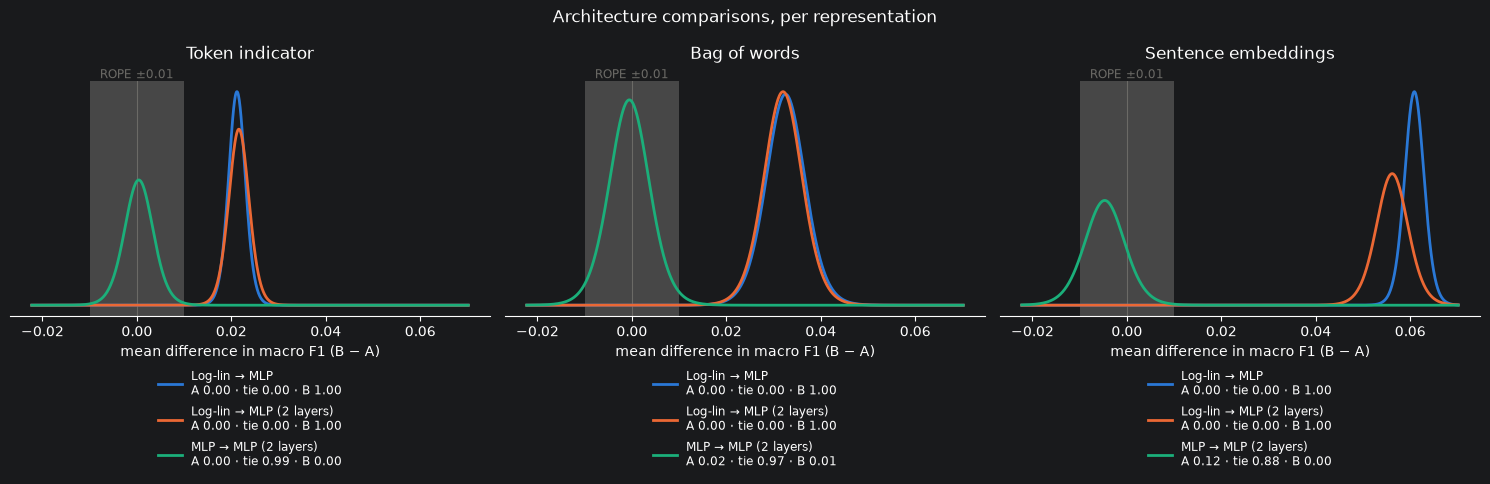

In [16]:
# per representation: does a more complex architecture help? (A -> B)
REP_NAMES = {"indicator-lemmas": "Token indicator", "bow-lemmas": "Bag of words", "embeddings": "Sentence embeddings"}
plot_posterior_panels(
    {title: [("Log-lin → MLP", f"logistic_{rep}", f"mlp_{rep}"),
             ("Log-lin → MLP (2 layers)", f"logistic_{rep}", f"mlp2_{rep}"),
             ("MLP → MLP (2 layers)", f"mlp_{rep}", f"mlp2_{rep}")]
     for rep, title in REP_NAMES.items()},
    "Architecture comparisons, per representation",
)

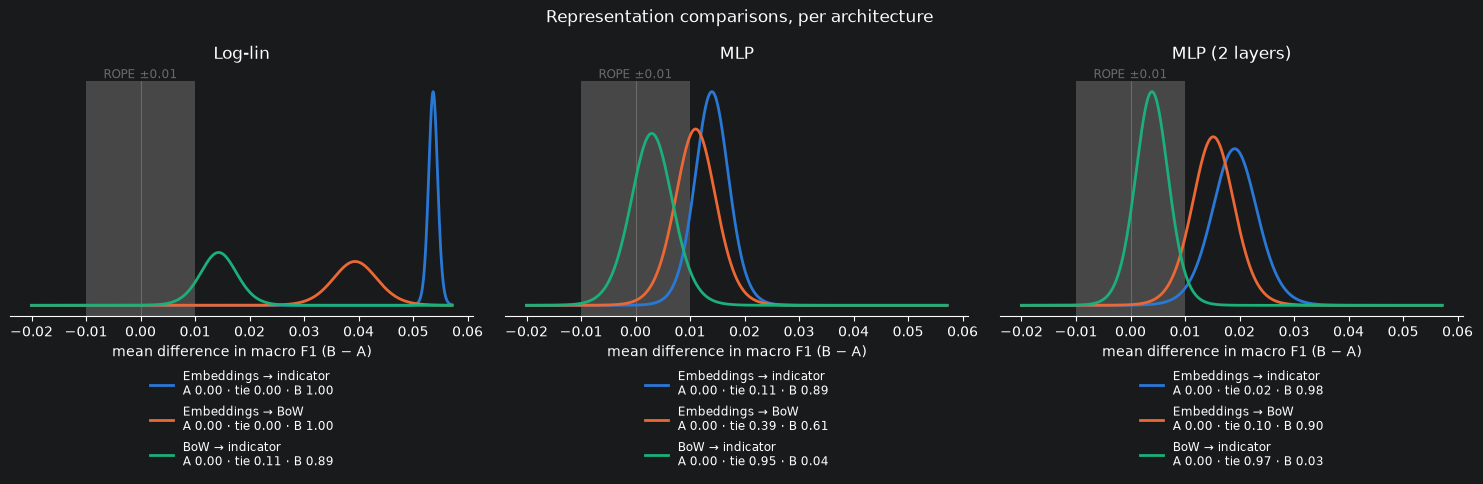

In [17]:
# per architecture: which representation is best? (A -> B)
ARCH_NAMES = {"logistic": "Log-lin", "mlp": "MLP", "mlp2": "MLP (2 layers)"}
plot_posterior_panels(
    {title: [("Embeddings → indicator", f"{arch}_embeddings", f"{arch}_indicator-lemmas"),
             ("Embeddings → BoW", f"{arch}_embeddings", f"{arch}_bow-lemmas"),
             ("BoW → indicator", f"{arch}_bow-lemmas", f"{arch}_indicator-lemmas")]
     for arch, title in ARCH_NAMES.items()},
    "Representation comparisons, per architecture",
)

### Forest plot
All comparisons in one view: one row per comparison (A → B), the dot is the posterior mean difference (B − A) and the line
its 95% interval. The shaded band is the ROPE. On the right, the decision, naming the better system: the region with posterior probability of at
least `DECISION_PROB`, or "undecided" (with the largest region's probability).

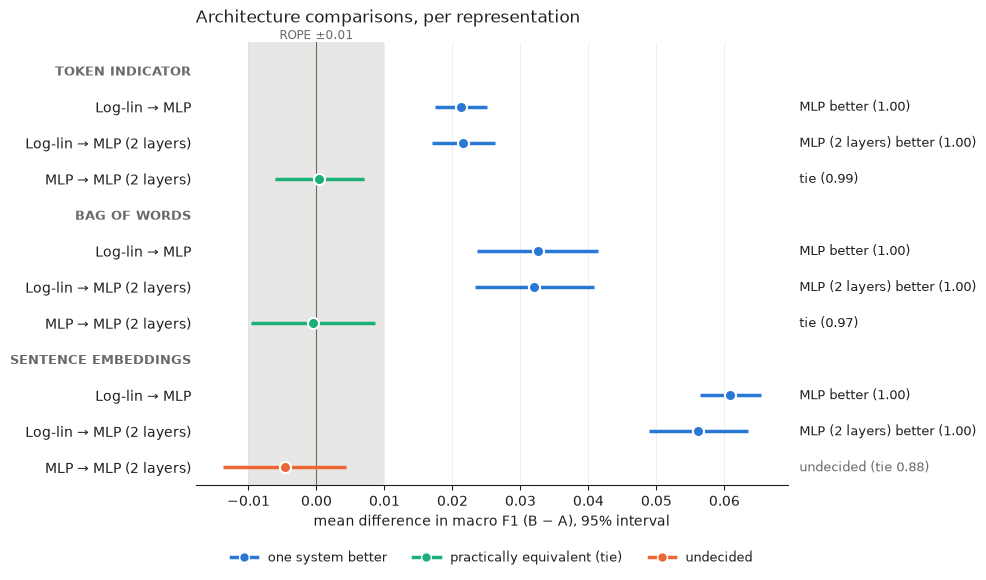

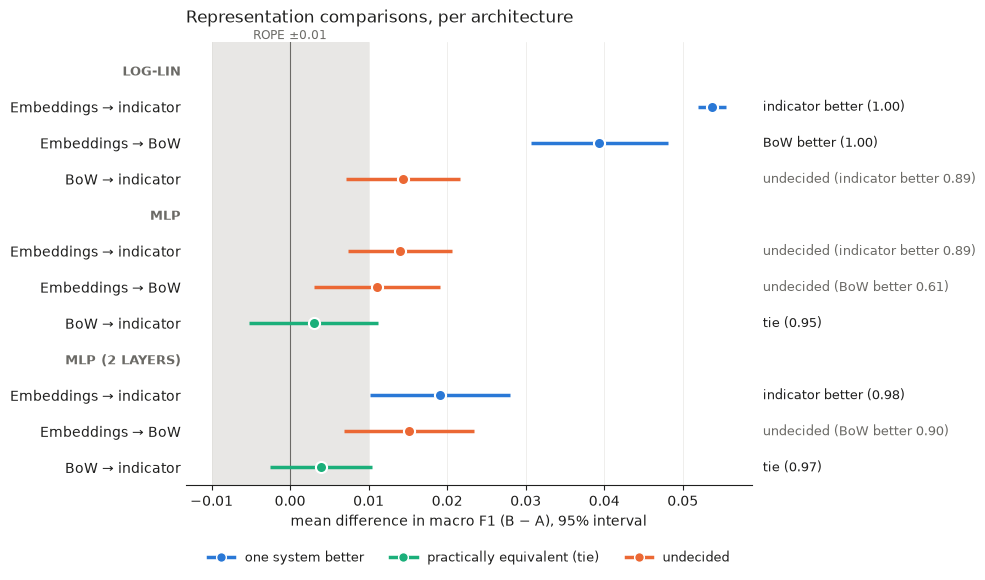

In [20]:
from matplotlib.lines import Line2D

# mark colour by result (categorical slots 1-3); the text stays in ink so it is readable on any colour
RESULT_COLOURS = {"better": "#2a78d6", "tie": "#1baf7a", "undecided": "#eb6834"}

# dark text and axes on the white background, whatever matplotlib theme the notebook runs with
LIGHT_STYLE = {"text.color": "#1f1f1e", "axes.labelcolor": "#1f1f1e", "axes.titlecolor": "#1f1f1e",
               "xtick.color": "#1f1f1e", "ytick.color": "#1f1f1e", "xtick.labelcolor": "#1f1f1e",
               "ytick.labelcolor": "#1f1f1e", "axes.edgecolor": "#1f1f1e", "legend.labelcolor": "#1f1f1e",
               "figure.facecolor": "white", "axes.facecolor": "white", "savefig.facecolor": "white"}

def plot_forest(*args, **kwargs):
    """See _plot_forest; draws it with the light style."""
    with plt.rc_context(LIGHT_STYLE):
        _plot_forest(*args, **kwargs)

def _plot_forest(groups, title, metric="f1", rope_size=ROPE_SIZE, decision_prob=DECISION_PROB, interval=0.95, save_as=None):
    """groups: {group heading: [(row label, sys_a, sys_b), ...]}. One row per comparison, grouped under headings.
    save_as: optional file name in figures/ (white background, for slides)."""
    rows = []  # (y label, posterior or None for a heading)
    for heading, pairs in groups.items():
        present = [(label, compare(a, b, metric)) for label, a, b in pairs if {a, b} <= available]
        if present:
            rows.append((heading, None))
            rows.extend(present)

    ink, muted = "#1f1f1e", "#6b6a66"
    fig, ax = plt.subplots(figsize=(10, 0.36 * len(rows) + 1.6), facecolor="white")
    ax.set_facecolor("white")
    ax.axvspan(-rope_size, rope_size, color="#b4b2ab", alpha=0.3, lw=0)
    ax.axvline(0, color=muted, lw=0.8)
    for y, (label, p) in enumerate(rows):
        if p is None:
            continue
        p_a, p_tie, p_b = p.probs(rope_size)
        name_a, name_b = label.split(" → ")  # name the winner instead of "A" / "B"
        regions = {f"{name_a} better": p_a, "tie": p_tie, f"{name_b} better": p_b}
        best = max(regions, key=regions.get)
        result = "undecided" if regions[best] < decision_prob else ("tie" if best == "tie" else "better")
        lo, hi = st.t.interval(interval, p.df, p.mean_diff, p.std)
        ax.hlines(y, lo, hi, color=RESULT_COLOURS[result], lw=2.5)
        ax.plot(p.mean_diff, y, "o", color=RESULT_COLOURS[result], ms=8, mec="white", mew=1.5)
        decision = f"{best} ({regions[best]:.2f})" if regions[best] >= decision_prob else f"undecided ({best} {regions[best]:.2f})"
        ax.text(1.02, y, decision, transform=ax.get_yaxis_transform(), va="center", fontsize=9.5,
                color=ink if regions[best] >= decision_prob else muted)

    ax.set_yticks(range(len(rows)), [label if p is not None else label.upper() for label, p in rows])
    for tick, (_, p) in zip(ax.get_yticklabels(), rows):
        if p is None:
            tick.set_fontweight("bold"); tick.set_fontsize(9); tick.set_color(muted)
    ax.set_ylim(len(rows) - 0.5, -0.8)  # first row at the top
    ax.text(0, -0.8, f"ROPE ±{rope_size}", ha="center", va="bottom", fontsize=8.5, color=muted)
    ax.set_xlabel(f"mean difference in {'macro F1' if metric == 'f1' else metric} (B − A), {interval:.0%} interval")
    ax.tick_params(axis="y", length=0)
    ax.spines[["left", "top", "right"]].set_visible(False)
    ax.grid(axis="x", color="#d9d8d4", alpha=0.6)
    ax.set_title(title, loc="left", fontsize=12, pad=14)
    handles = [Line2D([], [], color=colour, lw=2.5, marker="o", ms=7, mec="white", label=name)
               for name, colour in [("one system better", RESULT_COLOURS["better"]),
                                    ("practically equivalent (tie)", RESULT_COLOURS["tie"]),
                                    ("undecided", RESULT_COLOURS["undecided"])]]
    ax.legend(handles=handles, loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=3, frameon=False, fontsize=9.5)
    fig.tight_layout()
    if save_as:
        fig.savefig(Path("./figures") / save_as, dpi=200, bbox_inches="tight", facecolor="white")
    plt.show()

plot_forest(
    {title: [("Log-lin → MLP", f"logistic_{rep}", f"mlp_{rep}"),
             ("Log-lin → MLP (2 layers)", f"logistic_{rep}", f"mlp2_{rep}"),
             ("MLP → MLP (2 layers)", f"mlp_{rep}", f"mlp2_{rep}")]
     for rep, title in REP_NAMES.items()},
    "Architecture comparisons, per representation",
    save_as="rope_forest_architecture.png",
)
plot_forest(
    {title: [("Embeddings → indicator", f"{arch}_embeddings", f"{arch}_indicator-lemmas"),
             ("Embeddings → BoW", f"{arch}_embeddings", f"{arch}_bow-lemmas"),
             ("BoW → indicator", f"{arch}_bow-lemmas", f"{arch}_indicator-lemmas")]
     for arch, title in ARCH_NAMES.items()},
    "Representation comparisons, per architecture",
    save_as="rope_forest_representation.png",
)